# COVID-19 Wave Analysis

## Objective

This notebook identifies and analyzes distinct waves of COVID-19
in the United States using weekly reported case data.

The analysis will:
1. Load and validate the cleaned COVID-19 dataset.
2. Visualize weekly new cases over time.
3. Identify individual epidemic waves.
4. Calculate summary statistics for each wave.
5. Prepare wave-specific datasets for logistic model fitting.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

In [2]:
# Locate the project data file
possible_paths = [
    Path("../data/processed/us_covid_clean.csv"),
    Path("data/processed/us_covid_clean.csv"),
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find us_covid_clean.csv. "
        "Check that the data cleaning notebook has been run "
        "and that the CSV is saved in data/processed/."
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded from: {DATA_PATH}")
print(f"Dataset dimensions: {df.shape}")

df.head()

Dataset loaded from: ..\data\processed\us_covid_clean.csv
Dataset dimensions: (237, 7)


,week_ending,total_cases,total_deaths,new_cases,new_deaths,week,cases_reported
0,2020-01-26,7,0,7.0,0.0,0,True
1,2020-02-02,9,0,2.0,0.0,1,True
2,2020-02-09,20,0,11.0,0.0,2,True
3,2020-02-16,24,0,4.0,0.0,3,True
4,2020-02-23,40,0,16.0,0.0,4,True


In [3]:
# Inspect available columns and data types
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Columns:
['week_ending', 'total_cases', 'total_deaths', 'new_cases', 'new_deaths', 'week', 'cases_reported']

Data types:
week_ending           str
total_cases         int64
total_deaths        int64
new_cases         float64
new_deaths        float64
week                int64
cases_reported       bool
dtype: object

Missing values:
week_ending       0
total_cases       0
total_deaths      0
new_cases         0
new_deaths        0
week              0
cases_reported    0
dtype: int64


In [4]:
# Convert dates to datetime
df["week_ending"] = pd.to_datetime(df["week_ending"])

# Sort chronologically
df = df.sort_values("week_ending").reset_index(drop=True)

# Inspect weekly case counts
print(df[["week_ending", "new_cases"]].describe())

df[["week_ending", "new_cases"]].head()

               week_ending     new_cases
count                  237  2.370000e+02
mean   2022-05-01 00:00:00  4.364423e+05
min    2020-01-26 00:00:00  0.000000e+00
25%    2021-03-14 00:00:00  0.000000e+00
50%    2022-05-01 00:00:00  2.673040e+05
75%    2023-06-18 00:00:00  5.470860e+05
max    2024-08-04 00:00:00  5.650933e+06
std                    NaN  7.148681e+05


,week_ending,new_cases
0,2020-01-26,7.0
1,2020-02-02,2.0
2,2020-02-09,11.0
3,2020-02-16,4.0
4,2020-02-23,16.0


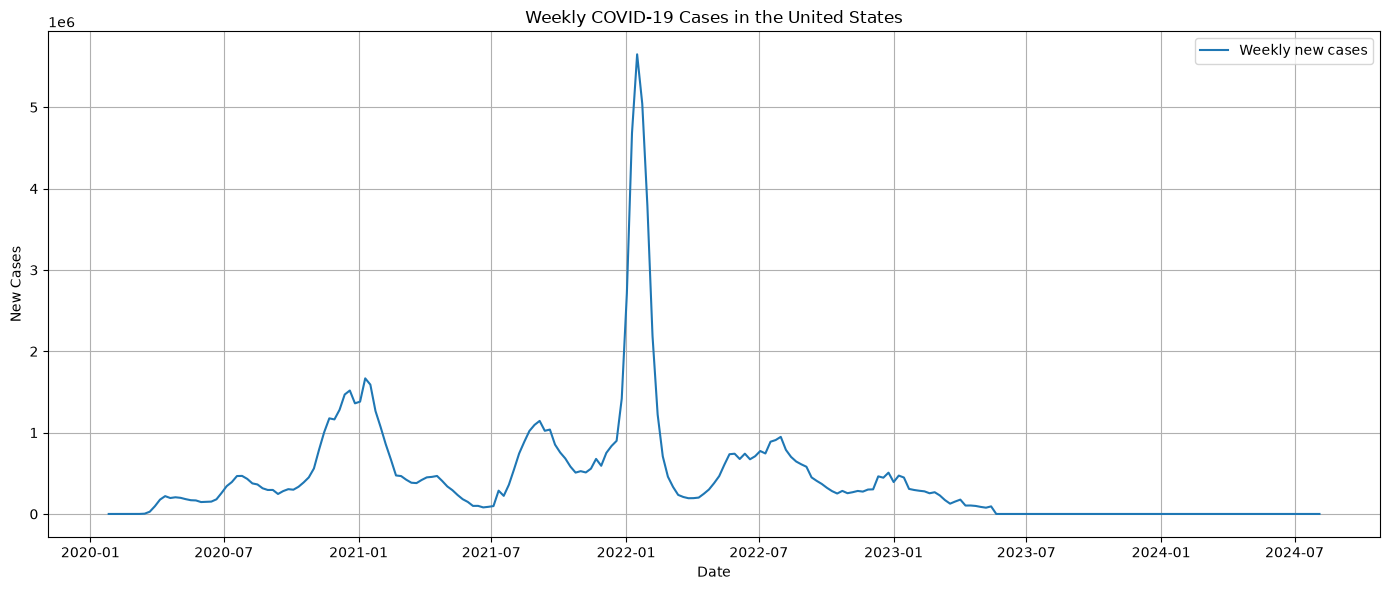

In [5]:
# Ensure weekly cases are numeric
df["new_cases"] = pd.to_numeric(df["new_cases"], errors="coerce")

# Remove rows with missing dates or case counts
wave_df = df.dropna(subset=["week_ending", "new_cases"]).copy()

# Sort chronologically
wave_df = wave_df.sort_values("week_ending").reset_index(drop=True)

# Plot weekly new cases
plt.figure(figsize=(14, 6))

plt.plot(
    wave_df["week_ending"],
    wave_df["new_cases"],
    label="Weekly new cases"
)

plt.title("Weekly COVID-19 Cases in the United States")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.legend()
plt.tight_layout()
plt.show()

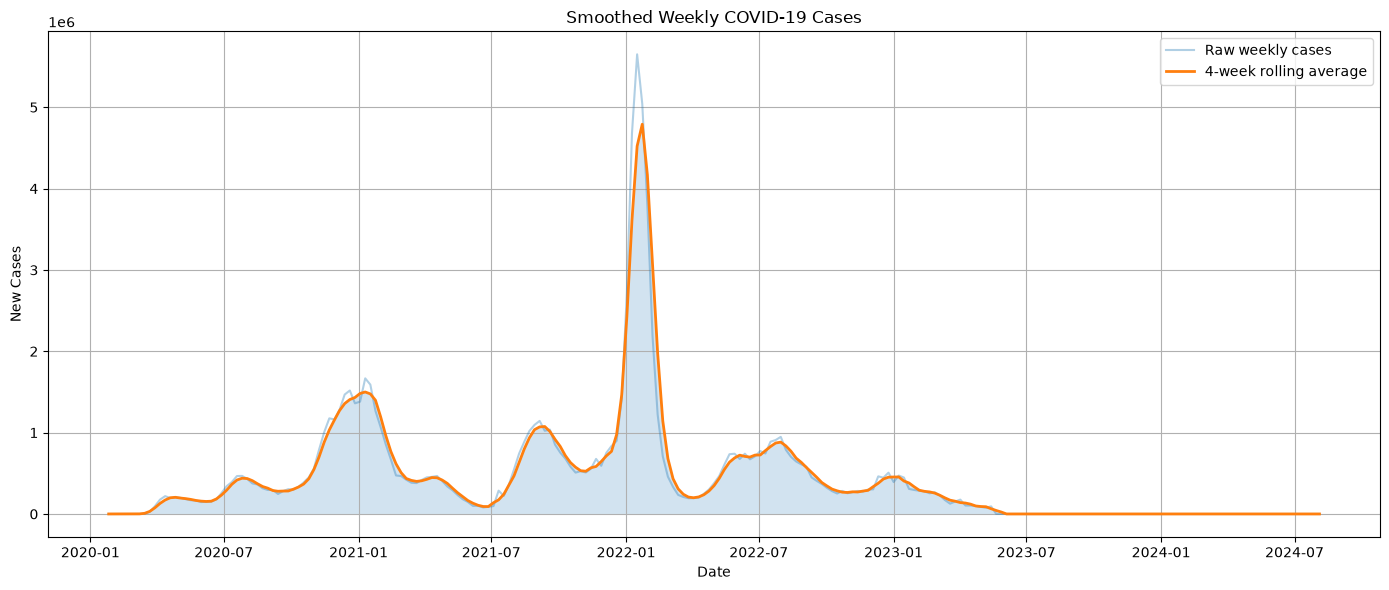

In [11]:
# Calculate a four-week rolling average
wave_df["cases_smoothed"] = (
    wave_df["new_cases"]
    .rolling(window=4, center=True, min_periods=2)
    .mean()
)

# Plot raw and smoothed cases
plt.figure(figsize=(14, 6))

plt.plot(
    wave_df["week_ending"],
    wave_df["new_cases"],
    alpha=0.35,
    label="Raw weekly cases"
)

plt.plot(
    wave_df["week_ending"],
    wave_df["cases_smoothed"],
    linewidth=2,
    label="4-week rolling average"
)

plt.title("Smoothed Weekly COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.fill_between(
    wave_df["week_ending"], 
    wave_df["cases_smoothed"], 
    alpha=0.2
)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
from scipy.signal import find_peaks

# Identify peaks in the smoothed case counts
cases = wave_df["cases_smoothed"].to_numpy()

peaks, properties = find_peaks(
    cases,
    distance=8,                 # At least 8 weeks between peaks
    prominence=cases.max() * 0.03
)

# Store detected peaks
peak_df = wave_df.iloc[peaks][
    ["week_ending", "cases_smoothed"]
].copy()

peak_df = peak_df.rename(
    columns={"cases_smoothed": "peak_cases"}
)

print(f"Number of potential waves: {len(peak_df)}")
peak_df

Number of potential waves: 6


,week_ending,peak_cases
26,2020-07-26,439405.75
50,2021-01-10,1499555.75
85,2021-09-12,1074791.25
104,2022-01-23,4791495.00
131,2022-07-31,883239.50
154,2023-01-08,455004.50


In [13]:
# Find the minimum case count between consecutive peaks
valleys = []

for i in range(len(peaks) - 1):
    left_peak = peaks[i]
    right_peak = peaks[i + 1]

    # Find the minimum between the two peaks
    valley = left_peak + np.argmin(
        cases[left_peak:right_peak + 1]
    )

    valleys.append(valley)

# Display valley dates
valley_df = wave_df.iloc[valleys][
    ["week_ending", "cases_smoothed"]
].copy()

valley_df = valley_df.rename(
    columns={"cases_smoothed": "valley_cases"}
)

valley_df

,week_ending,valley_cases
33,2020-09-13,279199.25
74,2021-06-27,91216.50
93,2021-11-07,525530.00
114,2022-04-03,199466.25
144,2022-10-30,264368.50


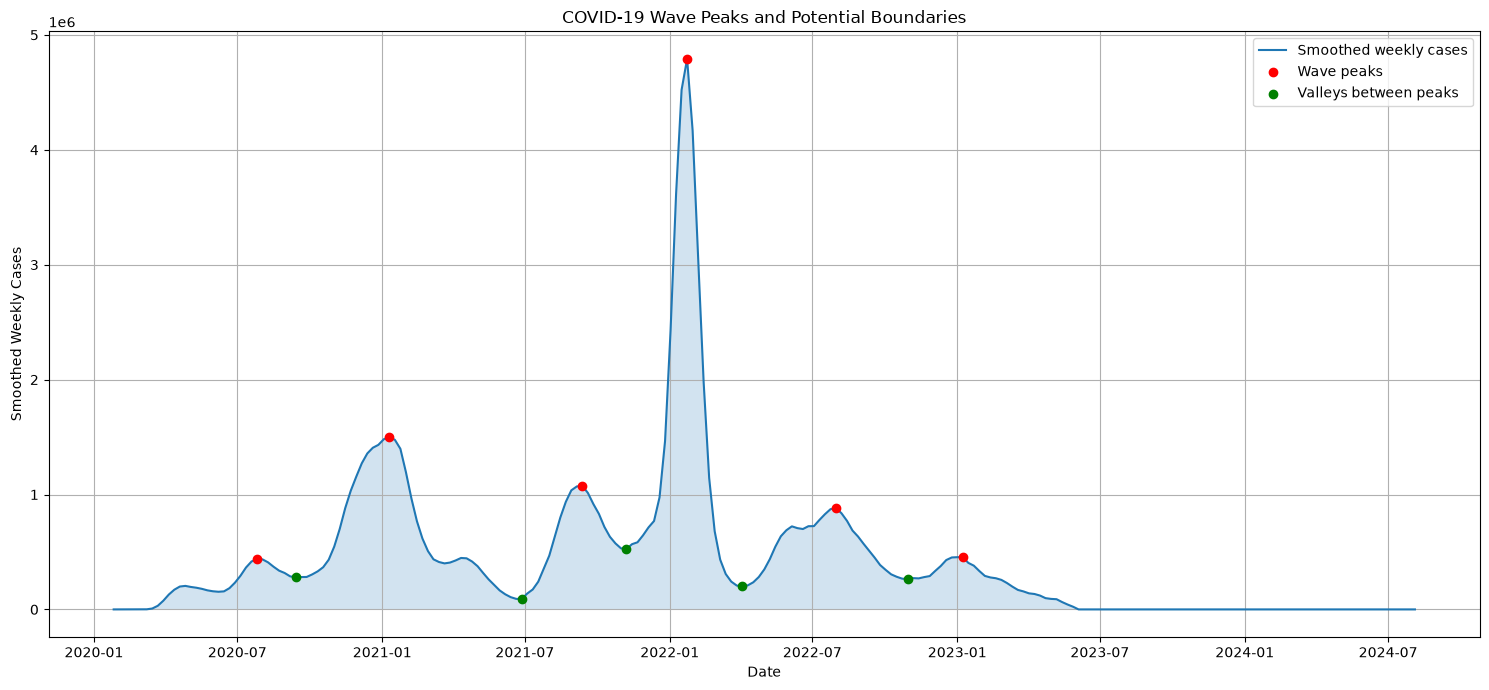

In [16]:
plt.figure(figsize=(15, 7))

plt.plot(
    wave_df["week_ending"],
    wave_df["cases_smoothed"],
    label="Smoothed weekly cases"
)

plt.scatter(
    wave_df.iloc[peaks]["week_ending"],
    wave_df.iloc[peaks]["cases_smoothed"],
    color="red",
    label="Wave peaks",
    zorder=3
)

plt.scatter(
    wave_df.iloc[valleys]["week_ending"],
    wave_df.iloc[valleys]["cases_smoothed"],
    color="green",
    label="Valleys between peaks",
    zorder=3
)

plt.title("COVID-19 Wave Peaks and Potential Boundaries")
plt.xlabel("Date")
plt.ylabel("Smoothed Weekly Cases")
plt.legend()
plt.fill_between(
    wave_df["week_ending"], 
    wave_df["cases_smoothed"], 
    alpha=0.2
)
plt.tight_layout()
plt.show()

In [17]:
# Create wave intervals
boundaries = [0] + valleys + [len(wave_df) - 1]

waves = []

for i in range(len(boundaries) - 1):
    start_idx = boundaries[i]
    end_idx = boundaries[i + 1]

    wave = wave_df.iloc[start_idx:end_idx + 1].copy()

    waves.append(wave)

print(f"Number of identified wave intervals: {len(waves)}")

Number of identified wave intervals: 6


In [18]:
# Calculate summary statistics for each wave
wave_summaries = []

for i, wave in enumerate(waves, start=1):

    # Find the peak within this wave
    peak_idx = wave["cases_smoothed"].idxmax()
    peak_row = wave.loc[peak_idx]

    # Calculate duration
    duration = (
        wave["week_ending"].iloc[-1]
        - wave["week_ending"].iloc[0]
    ).days / 7

    summary = {
        "wave": i,
        "start_date": wave["week_ending"].iloc[0],
        "end_date": wave["week_ending"].iloc[-1],
        "peak_date": peak_row["week_ending"],
        "peak_cases": peak_row["cases_smoothed"],
        "total_cases": wave["new_cases"].sum(),
        "duration_weeks": round(duration, 1)
    }

    wave_summaries.append(summary)

# Convert summaries into a DataFrame
wave_summary_df = pd.DataFrame(wave_summaries)

wave_summary_df

,wave,start_date,end_date,peak_date,peak_cases,total_cases,duration_weeks
0,1,2020-01-26,2020-09-13,2020-07-26,439405.75,6515345.0,33.0
1,2,2020-09-13,2021-06-27,2021-01-10,1499555.75,27002139.0,41.0
2,3,2021-06-27,2021-11-07,2021-09-12,1074791.25,12965670.0,19.0
3,4,2021-11-07,2022-04-03,2022-01-23,4791495.00,33857957.0,21.0
4,5,2022-04-03,2022-10-30,2022-07-31,883239.50,16872114.0,30.0
5,6,2022-10-30,2024-08-04,2023-01-08,455004.50,7516693.0,92.0


In [19]:
# Format numerical columns
wave_summary_df["peak_cases"] = (
    wave_summary_df["peak_cases"].round(0).astype("Int64")
)

wave_summary_df["total_cases"] = (
    wave_summary_df["total_cases"].round(0).astype("Int64")
)

wave_summary_df

,wave,start_date,end_date,peak_date,peak_cases,total_cases,duration_weeks
0,1,2020-01-26,2020-09-13,2020-07-26,439406,6515345,33.0
1,2,2020-09-13,2021-06-27,2021-01-10,1499556,27002139,41.0
2,3,2021-06-27,2021-11-07,2021-09-12,1074791,12965670,19.0
3,4,2021-11-07,2022-04-03,2022-01-23,4791495,33857957,21.0
4,5,2022-04-03,2022-10-30,2022-07-31,883240,16872114,30.0
5,6,2022-10-30,2024-08-04,2023-01-08,455004,7516693,92.0


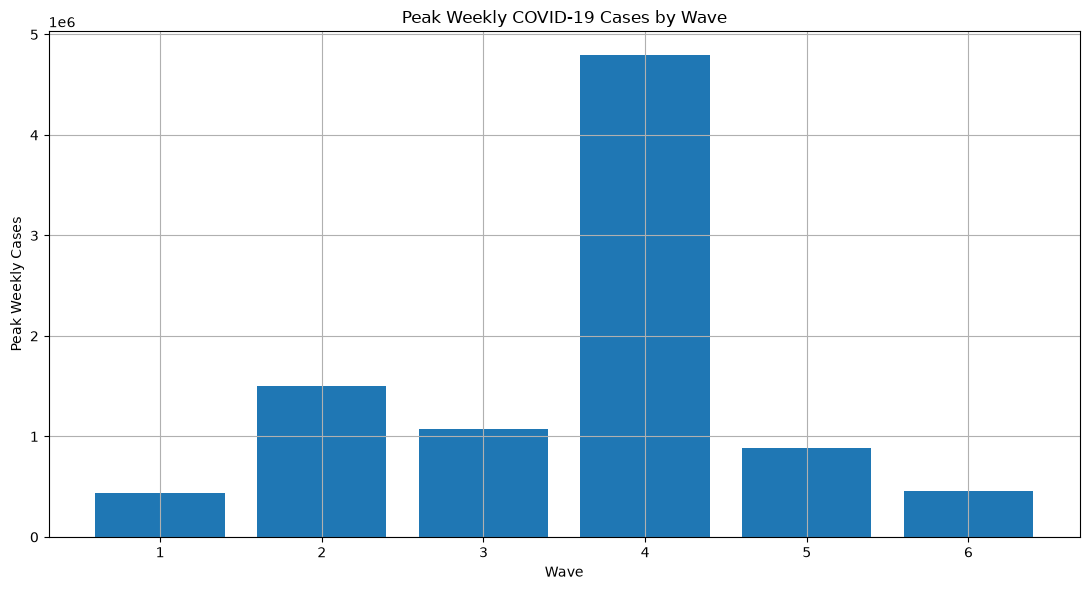

In [20]:
plt.figure(figsize=(11, 6))

plt.bar(
    wave_summary_df["wave"].astype(str),
    wave_summary_df["peak_cases"]
)

plt.title("Peak Weekly COVID-19 Cases by Wave")
plt.xlabel("Wave")
plt.ylabel("Peak Weekly Cases")
plt.tight_layout()
plt.show()

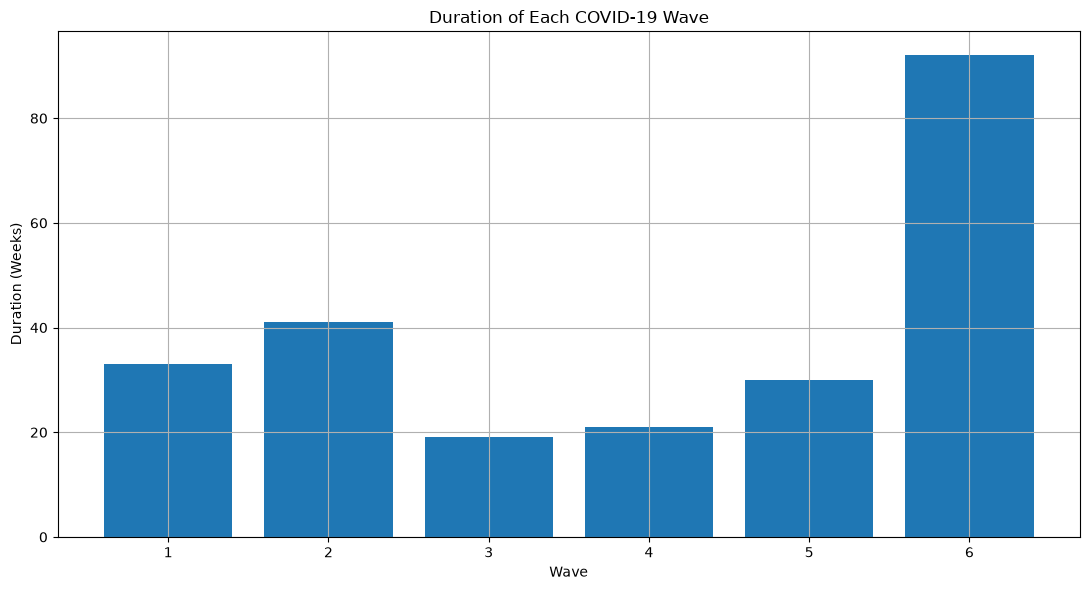

In [21]:
plt.figure(figsize=(11, 6))

plt.bar(
    wave_summary_df["wave"].astype(str),
    wave_summary_df["duration_weeks"]
)

plt.title("Duration of Each COVID-19 Wave")
plt.xlabel("Wave")
plt.ylabel("Duration (Weeks)")
plt.tight_layout()
plt.show()

In [23]:
# Create output directory if necessary
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Export summary
summary_path = output_dir / "us_covid_waves.csv"

wave_summary_df.to_csv(summary_path, index=False)

print(f"Wave summary saved to: {summary_path}")

Wave summary saved to: ..\data\processed\us_covid_waves.csv


In [24]:
# Rebuild wave intervals without duplicated boundary weeks
waves = []

start_idx = 0

for valley in valleys:
    wave = wave_df.iloc[start_idx:valley + 1].copy()
    waves.append(wave)

    start_idx = valley + 1

# Add the final interval
if start_idx < len(wave_df):
    waves.append(wave_df.iloc[start_idx:].copy())

print(f"Number of wave datasets: {len(waves)}")

Number of wave datasets: 6


In [25]:
# Prepare individual wave datasets
prepared_waves = []

for i, wave in enumerate(waves, start=1):
    wave = wave.copy().reset_index(drop=True)

    wave["wave"] = i
    wave["week_number"] = np.arange(len(wave))
    wave["elapsed_weeks"] = wave["week_number"]

    wave["cumulative_cases_in_wave"] = (
        wave["new_cases"].cumsum()
    )

    prepared_waves.append(wave)

# Preview the first wave
prepared_waves[0].head()

,week_ending,total_cases,total_deaths,new_cases,new_deaths,week,cases_reported,cases_smoothed,wave,week_number,elapsed_weeks,cumulative_cases_in_wave
0,2020-01-26,7,0,7.0,0.0,0,True,4.500000,1,0,0,7.0
1,2020-02-02,9,0,2.0,0.0,1,True,6.666667,1,1,1,9.0
2,2020-02-09,20,0,11.0,0.0,2,True,6.000000,1,2,2,20.0
3,2020-02-16,24,0,4.0,0.0,3,True,8.250000,1,3,3,24.0
4,2020-02-23,40,0,16.0,0.0,4,True,16.000000,1,4,4,40.0


In [26]:
# Create output directory
wave_output_dir = Path("../data/processed/waves")
wave_output_dir.mkdir(parents=True, exist_ok=True)

# Export each wave
for i, wave in enumerate(prepared_waves, start=1):
    filename = f"us_covid_wave_{i}.csv"
    filepath = wave_output_dir / filename

    wave.to_csv(filepath, index=False)

    print(f"Saved: {filepath}")

Saved: ..\data\processed\waves\us_covid_wave_1.csv
Saved: ..\data\processed\waves\us_covid_wave_2.csv
Saved: ..\data\processed\waves\us_covid_wave_3.csv
Saved: ..\data\processed\waves\us_covid_wave_4.csv
Saved: ..\data\processed\waves\us_covid_wave_5.csv
Saved: ..\data\processed\waves\us_covid_wave_6.csv


In [27]:
# Combine all prepared wave datasets
all_waves_df = pd.concat(
    prepared_waves,
    ignore_index=True
)

# Export combined dataset
combined_path = Path("../data/processed/us_covid_all_waves.csv")

all_waves_df.to_csv(combined_path, index=False)

print(f"Combined dataset saved to: {combined_path}")

all_waves_df.head()

Combined dataset saved to: ..\data\processed\us_covid_all_waves.csv


,week_ending,total_cases,total_deaths,new_cases,new_deaths,week,cases_reported,cases_smoothed,wave,week_number,elapsed_weeks,cumulative_cases_in_wave
0,2020-01-26,7,0,7.0,0.0,0,True,4.500000,1,0,0,7.0
1,2020-02-02,9,0,2.0,0.0,1,True,6.666667,1,1,1,9.0
2,2020-02-09,20,0,11.0,0.0,2,True,6.000000,1,2,2,20.0
3,2020-02-16,24,0,4.0,0.0,3,True,8.250000,1,3,3,24.0
4,2020-02-23,40,0,16.0,0.0,4,True,16.000000,1,4,4,40.0
